# Homework 1: Bass Diffusion Model

**Samsung Micro RGB TV**, forecast using OLED TVs as the look-alike innovation.

The full write-up is in `report/report.pdf`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

## Bass model functions

In [2]:
def bass_model(p, q, M, periods):
    """Discrete-time Bass model.

    N_t = (p + q * A_(t-1) / M) * (M - A_(t-1))

    Returns the new adopters in each period and the cumulative adopters
    at the end of each period. Cumulative adoption starts at 0.
    """
    cumulative = 0.0
    new_adopters = []
    cumulative_adopters = []

    for t in range(periods):
        n_t = (p + q * cumulative / M) * (M - cumulative)
        cumulative += n_t
        new_adopters.append(n_t)
        cumulative_adopters.append(cumulative)

    return np.array(new_adopters), np.array(cumulative_adopters)


def fit_bass(sales, p0=0.01, q0=0.4, M0=None):
    """Estimate p, q and M with nonlinear least squares."""
    sales = np.asarray(sales, dtype=float)
    if M0 is None:
        M0 = sales.sum() * 1.5

    def residuals(params):
        p, q, M = params
        predicted, _ = bass_model(p, q, M, len(sales))
        return predicted - sales

    result = least_squares(
        residuals,
        x0=[p0, q0, M0],
        bounds=([1e-6, 1e-6, sales.sum()], [1, 3, sales.sum() * 50]),
    )
    return result.x


def rmse(actual, predicted):
    return np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2))


def r_squared(actual, predicted):
    actual = np.asarray(actual)
    ss_res = np.sum((actual - np.asarray(predicted)) ** 2)
    ss_tot = np.sum((actual - actual.mean()) ** 2)
    return 1 - ss_res / ss_tot

## 1. Look-alike data: OLED TV shipments (2015–2025)

In [3]:
# Worldwide OLED TV shipments, millions of units (IHS Markit / Omdia, see report for sources)
oled = pd.read_csv("data/oled_tv_shipments.csv")
display(oled)

,year,shipments_millions
0,2015,0.335
1,2016,0.724
2,2017,1.590
3,2018,2.600
4,2019,3.000
5,2020,3.600
6,2021,6.500
7,2022,6.500
8,2023,5.600
9,2024,6.070


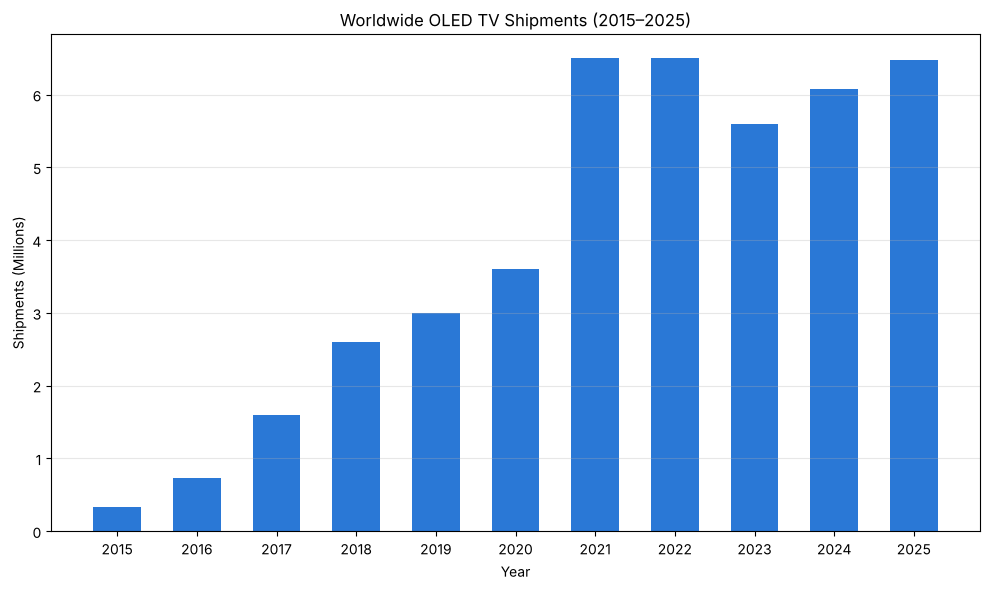

In [4]:
plt.figure(figsize=(10, 6))
plt.bar(oled["year"], oled["shipments_millions"], color="#2a78d6", width=0.6)

plt.title("Worldwide OLED TV Shipments (2015–2025)")
plt.xlabel("Year")
plt.ylabel("Shipments (Millions)")
plt.xticks(oled["year"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("img/oled_annual_shipments.png", dpi=300)
plt.show()

## 2. Estimating the Bass model parameters

In [5]:
# Discrete-time Bass model: N_t = (p + q * A_(t-1) / M) * (M - A_(t-1))
# Cumulative adoption starts at 0 before 2015.
years = oled["year"].to_numpy()
sales = oled["shipments_millions"].to_numpy()

p, q, M = fit_bass(sales, p0=0.005, q0=0.5, M0=80)

print(f"p = {p:.4f}")
print(f"q = {q:.3f}")
print(f"M = {M:.1f} million")
print(f"q/p = {q/p:.1f}")

p = 0.0151
q = 0.440
M = 56.7 million
q/p = 29.1


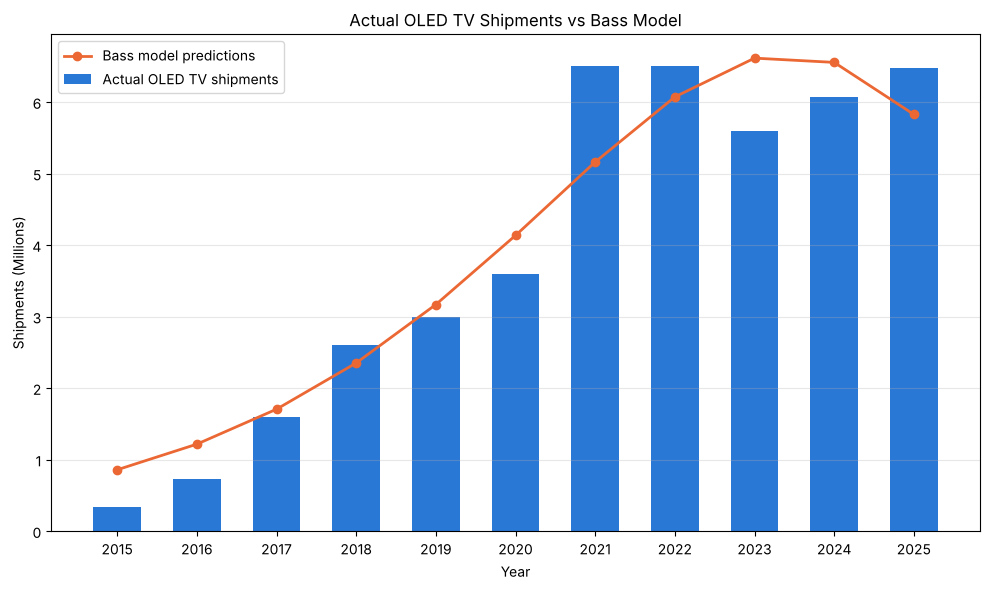

In [6]:
predicted, _ = bass_model(p, q, M, len(years))

plt.figure(figsize=(10, 6))
plt.bar(years, sales, color="#2a78d6", width=0.6, label="Actual OLED TV shipments")
plt.plot(years, predicted, marker="o", color="#eb6834", linewidth=2, label="Bass model predictions")

plt.title("Actual OLED TV Shipments vs Bass Model")
plt.xlabel("Year")
plt.ylabel("Shipments (Millions)")
plt.xticks(years)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("img/oled_bass_model_comparison.png", dpi=300)
plt.show()

In [7]:
print(f"RMSE: {rmse(sales, predicted):.4f} million units")
print(f"R-squared: {r_squared(sales, predicted):.4f}")

fit_results = pd.DataFrame({
    "Year": years,
    "Actual_Shipments_Millions": sales,
    "Bass_Predictions_Millions": predicted.round(3),
})
display(fit_results)
fit_results.to_csv("data/oled_bass_fit_results.csv", index=False)

RMSE: 0.6436 million units
R-squared: 0.9220


,Year,Actual_Shipments_Millions,Bass_Predictions_Millions
0,2015,0.335,0.858
1,2016,0.724,1.216
2,2017,1.590,1.704
3,2018,2.600,2.351
4,2019,3.000,3.168
5,2020,3.600,4.134
6,2021,6.500,5.161
7,2022,6.500,6.071
8,2023,5.600,6.613
9,2024,6.070,6.554


## 3. Market potential for Micro RGB / RGB LED TVs (Fermi estimate)

M = (TV shipments per year) × (RGB LED share of TV units) × (years the technology stays a leading premium option)

* Global TV shipments 2026: 194.65 million (TrendForce)
* RGB LED share: Omdia expects 7.1M RGB LED TVs in 2030, which is about 3.6% of ~195M TVs
* Life cycle: OLED took about 10 years (2015–2025) to reach its plateau

In [8]:
tv_shipments = 194.65   # millions per year

scenarios = pd.DataFrame({
    "scenario": ["low", "base", "high"],
    "rgb_share": [0.025, 0.036, 0.05],
    "life_cycle_years": [8, 10, 12],
})
scenarios["M_millions"] = tv_shipments * scenarios["rgb_share"] * scenarios["life_cycle_years"]
display(scenarios.round(2))

M_rgb = dict(zip(scenarios["scenario"], scenarios["M_millions"]))

,scenario,rgb_share,life_cycle_years,M_millions
0,low,0.02,8,38.93
1,base,0.04,10,70.07
2,high,0.05,12,116.79


## 4. Forecast of adopters by year (2025–2040)

In [9]:
# p and q are taken from OLED, M from the Fermi estimate.
# The forecast starts in 2025 (first Micro RGB TV) with 0 cumulative adopters.
forecast_years = np.arange(2025, 2041)

forecast = pd.DataFrame({"Year": forecast_years})
for s in ["low", "base", "high"]:
    new, cum = bass_model(p, q, M_rgb[s], len(forecast_years))
    forecast[f"New_Adopters_{s}"] = new
    forecast[f"Cumulative_{s}"] = cum

forecast = forecast.round(3)
display(forecast[["Year", "New_Adopters_base", "Cumulative_base", "New_Adopters_low", "New_Adopters_high"]])
forecast.to_csv("data/micro_rgb_forecast.csv", index=False)

peak_row = forecast.loc[forecast["New_Adopters_base"].idxmax()]
print(f"Base case peak: {peak_row['Year']:.0f} with {peak_row['New_Adopters_base']:.2f} million new adopters")

,Year,New_Adopters_base,Cumulative_base,New_Adopters_low,New_Adopters_high
0,2025,1.059,1.059,0.589,1.766
1,2026,1.502,2.561,0.834,2.503
2,2027,2.105,4.667,1.170,3.509
3,2028,2.904,7.570,1.613,4.840
4,2029,3.913,11.484,2.174,6.522
5,2030,5.107,16.591,2.837,8.511
6,2031,6.375,22.966,3.542,10.626
7,2032,7.500,30.466,4.166,12.499
8,2033,8.169,38.635,4.538,13.615
9,2034,8.096,46.730,4.498,13.493


Base case peak: 2033 with 8.17 million new adopters


In [10]:
# How does this compare with what analysts expect?
analysts = pd.read_csv("data/analyst_forecasts_rgb_tv.csv")
analysts["Bass_base_millions"] = analysts["year"].map(
    forecast.set_index("Year")["New_Adopters_base"])
display(analysts)

,year,shipments_millions,source,Bass_base_millions
0,2026,1.1,Omdia,1.502
1,2026,1.7,TrendForce,1.502
2,2030,7.1,Omdia,5.107


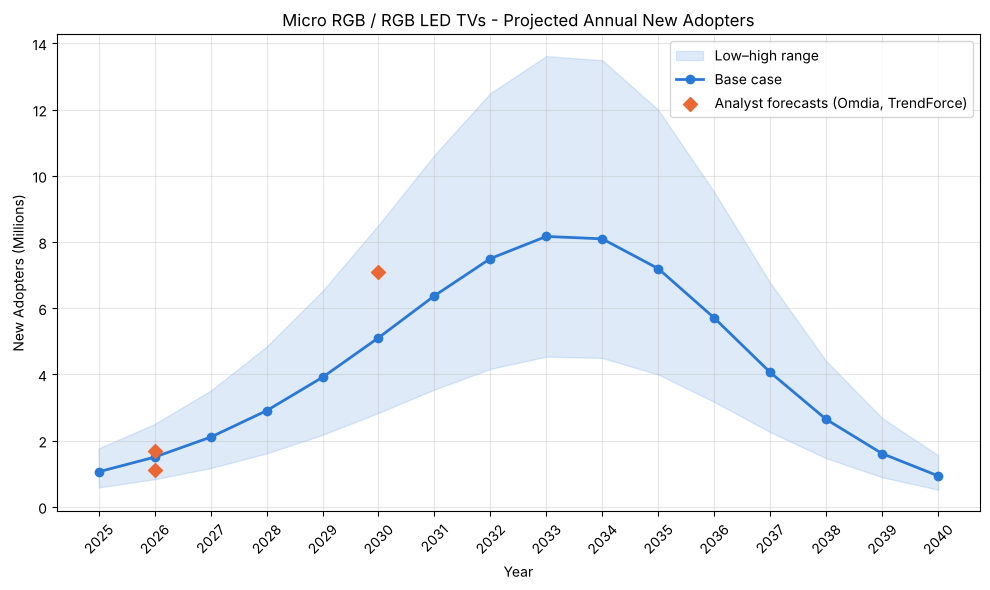

In [11]:
plt.figure(figsize=(10, 6))

plt.fill_between(forecast["Year"], forecast["New_Adopters_low"], forecast["New_Adopters_high"],
                 color="#2a78d6", alpha=0.15, label="Low–high range")
plt.plot(forecast["Year"], forecast["New_Adopters_base"], marker="o",
         color="#2a78d6", linewidth=2, label="Base case")
plt.scatter(analysts["year"], analysts["shipments_millions"], color="#eb6834",
            marker="D", s=50, zorder=3, label="Analyst forecasts (Omdia, TrendForce)")

plt.title("Micro RGB / RGB LED TVs - Projected Annual New Adopters")
plt.xlabel("Year")
plt.ylabel("New Adopters (Millions)")
plt.xticks(forecast_years, rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("img/micro_rgb_annual_adopters.png", dpi=300)
plt.show()

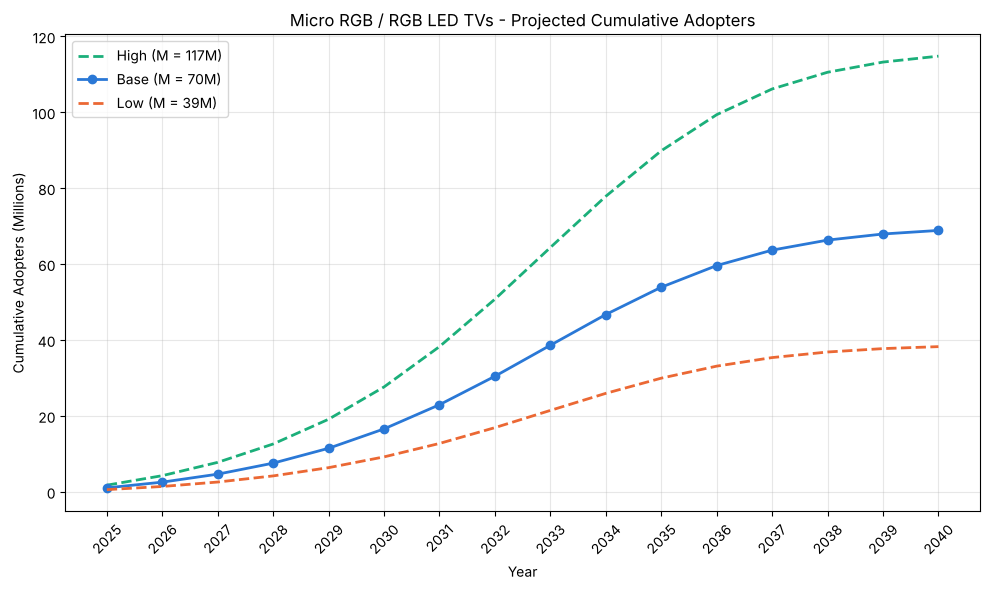

In [12]:
plt.figure(figsize=(10, 6))

plt.plot(forecast["Year"], forecast["Cumulative_high"], linestyle="--", color="#1baf7a",
         linewidth=2, label=f"High (M = {M_rgb['high']:.0f}M)")
plt.plot(forecast["Year"], forecast["Cumulative_base"], marker="o", color="#2a78d6",
         linewidth=2, label=f"Base (M = {M_rgb['base']:.0f}M)")
plt.plot(forecast["Year"], forecast["Cumulative_low"], linestyle="--", color="#eb6834",
         linewidth=2, label=f"Low (M = {M_rgb['low']:.0f}M)")

plt.title("Micro RGB / RGB LED TVs - Projected Cumulative Adopters")
plt.xlabel("Year")
plt.ylabel("Cumulative Adopters (Millions)")
plt.xticks(forecast_years, rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("img/micro_rgb_cumulative_adopters.png", dpi=300)
plt.show()

## 5. Sensitivity: what q would match Omdia's 2030 forecast?

RGB LED TVs are made on existing LCD lines and got cheap quickly, so they might spread faster than OLED did.

In [13]:
from scipy.optimize import brentq

def adopters_2030(q_value):
    new, _ = bass_model(p, q_value, M_rgb["base"], 6)   # 2025 ... 2030
    return new[-1]

q_omdia = brentq(lambda x: adopters_2030(x) - 7.1, q, 1.0)
new_fast, _ = bass_model(p, q_omdia, M_rgb["base"], len(forecast_years))

print(f"q needed for 7.1M in 2030: {q_omdia:.3f}")
print(f"2026 with this q: {new_fast[1]:.2f} million")
print(f"Peak year with this q: {forecast_years[new_fast.argmax()]} ({new_fast.max():.2f} million)")

q needed for 7.1M in 2030: 0.558
2026 with this q: 1.63 million
Peak year with this q: 2032 (10.18 million)
